In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [110]:
data = pd.read_csv("data/course_lead_scoring_2026.csv")
data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### Data preparation

Check if the missing values are presented in the features.
If there are missing values:
- For categorical features, replace them with 'NA'
- For numerical features, replace with with 0.0

In [111]:
data.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [112]:
cat = list(data.columns[data.dtypes == "string"])
data[cat] = data[cat].fillna('NA')

num = list(data.columns[data.dtypes != "string"])
num.remove('converted')
data[num] = data[num].fillna(0.0)
data.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Split the data into 3 parts with these exact calls:

In [113]:
df_full_train, df_test = train_test_split(data, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train['converted']
y_val = df_val['converted']
y_test = df_test['converted']

del df_train['converted']
del df_val['converted']
del df_test['converted']

### Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

- For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
- Use the training dataset for that
If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- lead_score
- number_of_courses_viewed
- interaction_count
- annual_income

In [114]:
FeatureScoreTuple = (" ", 0.0)
for feature in num:
	score = roc_auc_score(y_train, df_train[feature])
	score = max(score, 1 - score)
	if score > FeatureScoreTuple[1]:
		FeatureScoreTuple = feature, score
	print(f"ROC AUC Score of {feature}: {score}")
print(f"Highest ROC AUC Score is {FeatureScoreTuple[0]}")

ROC AUC Score of annual_income: 0.6081977776250831
ROC AUC Score of number_of_courses_viewed: 0.7229894623989618
ROC AUC Score of interaction_count: 0.7649203047563227
ROC AUC Score of lead_score: 0.7882254810906102
Highest ROC AUC Score is lead_score


### Question 2: Training the model
Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [115]:
def train_eval_proba_model(df_train, df_val, y_train, C=1.0):
	dv = DictVectorizer(sparse=False)
	X_train = dv.fit_transform(df_train.to_dict(orient='records'))
	X_val = dv.transform(df_val.to_dict(orient='records'))

	model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
	model.fit(X_train, y_train.values)

	return model.predict_proba(X_val)

y_pred = train_eval_proba_model(df_train=df_train, df_val=df_val, y_train=y_train)
score = roc_auc_score(y_val.values, y_pred[:, 1])
print(f"The AUC score is {round(score, 3)}")

The AUC score is 0.732


### Question 3: Precision and Recall
Now let's compute precision and recall for our model.

- Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
- For each threshold, compute precision and recall
- Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

- 0.43
- 0.63
- .73
- 0.83

<Axes: xlabel='Threshold'>

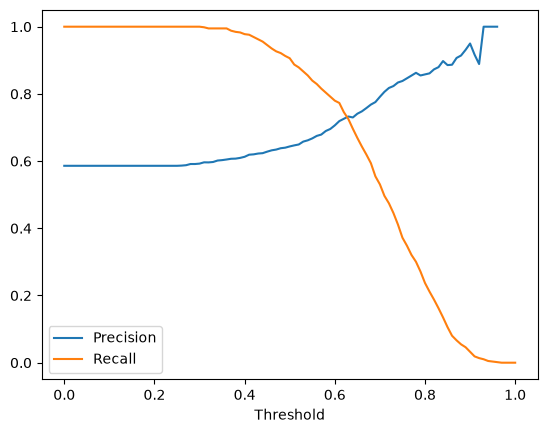

In [116]:
y_pred = train_eval_proba_model(df_train=df_train, df_val=df_val, y_train=y_train)

points = []

for t in np.arange(0.0, 1.01, 0.01):
	tp = ((y_pred[:,1] >= t) & (y_val == 1)).sum()
	fp = ((y_pred[:,1] >= t) & (y_val == 0)).sum()
	fn = ((y_pred[:,1] < t) & (y_val == 1)).sum()
 
	p = tp / (tp + fp) if tp != 0.0 else np.nan # Otherwise zero division error
	r = tp / (tp + fn)
	points.append((t, p ,r))

points_df = pd.DataFrame(points, columns=['Threshold', 'Precision', 'Recall']).set_index('Threshold')
points_df.plot()

In [117]:
points_df['Diff'] = abs(points_df['Precision'] - points_df['Recall'])
min_diff_t = points_df['Diff'].idxmin()

print(f"Smallest difference between recall and precision is at {min_diff_t}")

Smallest difference between recall and precision is at 0.63


### Question 4: F1 score
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:


$F1 = 2 . (P . R) / (P + R)$
 
Where 
P is precision and R is recall

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?
- 0.21
- 0.41
- 0.61
- 0.81

Max F1 score is at 0.410


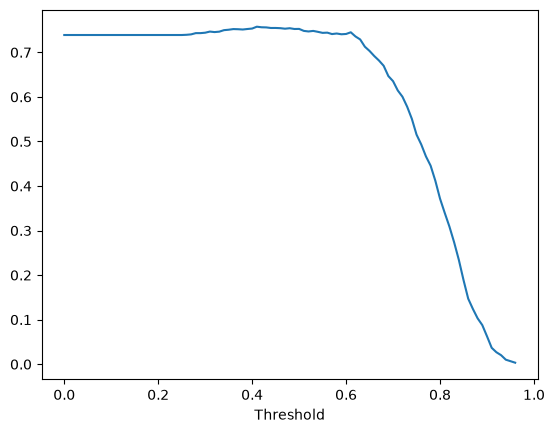

In [118]:
points_df['f1'] = 2 * (points_df['Precision'] * points_df['Recall']) / (points_df['Precision'] + points_df['Recall'])
max_f1_t = points_df['f1'].idxmax()
points_df['f1'].plot()
print(f"Max F1 score is at {max_f1_t:.3f}")

### Question 5: 5-Fold CV
Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)

- Iterate over different folds of df_full_train
- Split the data into train and validation
- Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0,max_iter=1000)
- Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [119]:
y_full = df_full_train['converted']
X_full = df_full_train.drop(columns='converted')

In [120]:
cv = KFold(n_splits=5, shuffle=True, random_state=1)
score = []

for train_idx, val_idx in cv.split(X_full):

    t_df = X_full.iloc[train_idx]	
    v_df = X_full.iloc[val_idx]
    y_t = y_full.iloc[train_idx]
    y_v = y_full.iloc[val_idx]
    
    y_pred = train_eval_proba_model(df_train=t_df, df_val=v_df,y_train=y_t)
    score.append(roc_auc_score(y_v, y_pred[:, 1]))

print(f"The standard deviation accross folds is {np.std(score): .3f}")

The standard deviation accross folds is  0.007


### Question 6: Hyperparameter Tuning
Now let's use 5-Fold cross-validation to find the best parameter C

- Iterate over the following C values: [0.000001, 0.001, 1]
- Initialize KFold with the same parameters as previously
- Use these parameters for the model: 

LogisticRegression(solver='liblinear', C=C, max_iter=1000)

- Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which C leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.

In [121]:
cv = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
	score = []
	for train_idx, val_idx in cv.split(X_full):

		t_df = X_full.iloc[train_idx]	
		v_df = X_full.iloc[val_idx]
		y_t = y_full.iloc[train_idx]
		y_v = y_full.iloc[val_idx]
		
		y_pred = train_eval_proba_model(df_train=t_df, df_val=v_df,y_train=y_t, C=C)
		score.append(roc_auc_score(y_v, y_pred[:, 1]))

	print(f"C = {C}, the  mean is {np.mean(score): .3f} and standard deviation : {np.std(score): .3f}")

C = 1e-06, the  mean is  0.617 and standard deviation :  0.019
C = 0.001, the  mean is  0.749 and standard deviation :  0.010
C = 1, the  mean is  0.732 and standard deviation :  0.007
